# JS13 - Praktikum 1: JST Sederhana 2-Layer dari Scratch (XOR)
**Mata Kuliah:** Pembelajaran Mesin  
**Nama:** Aryaputra | **NIM:** 244107020127  

---
### Deskripsi
Membangun Jaringan Saraf Tiruan 2-layer dari awal dengan forward pass, kalkulasi loss, backpropagation manual, dan optimasi gradient descent untuk menyelesaikan gerbang non-linier XOR (+ Tugas 1: 3 hidden neurons).


Prediksi Akhir (2 Neuron):
 [[0.05300376]
 [0.49554286]
 [0.95091752]
 [0.50319846]]
Prediksi Akhir (3 Neuron):
 [[0.02515318]
 [0.95264015]
 [0.95122762]
 [0.06271949]]


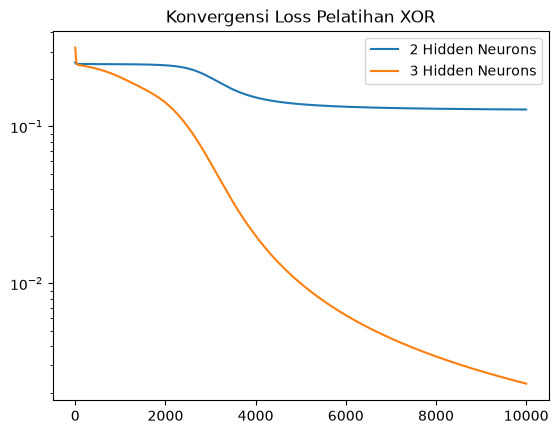

In [1]:
import numpy as np
import matplotlib.pyplot as plt

X = np.array([[0,0], [0,1], [1,0], [1,1]])
y = np.array([[0], [1], [1], [0]])

def sigmoid(x): return 1 / (1 + np.exp(-x))
def sigmoid_dev(x): return x * (1 - x)

def train_jst(hidden_units=2, lr=0.1, epochs=10000):
    np.random.seed(42)
    W1 = np.random.randn(2, hidden_units)
    b1 = np.zeros((1, hidden_units))
    W2 = np.random.randn(hidden_units, 1)
    b2 = np.zeros((1, 1))
    losses = []

    for epoch in range(epochs + 1):
        # Forward pass
        a1 = sigmoid(np.dot(X, W1) + b1)
        a2 = sigmoid(np.dot(a1, W2) + b2)

        error = y - a2
        loss = np.mean(np.square(error))
        losses.append(loss)

        # Backpropagation
        d_a2 = error * sigmoid_dev(a2)
        d_W2 = np.dot(a1.T, d_a2)
        d_b2 = np.sum(d_a2, axis=0, keepdims=True)

        d_a1 = np.dot(d_a2, W2.T) * sigmoid_dev(a1)
        d_W1 = np.dot(X.T, d_a1)
        d_b1 = np.sum(d_a1, axis=0, keepdims=True)

        W1 += lr * d_W1
        b1 += lr * d_b1
        W2 += lr * d_W2
        b2 += lr * d_b2

    return losses, a2

losses_2, pred_2 = train_jst(2)
losses_3, pred_3 = train_jst(3)

print("Prediksi Akhir (2 Neuron):\n", pred_2)
print("Prediksi Akhir (3 Neuron):\n", pred_3)

plt.plot(losses_2, label='2 Hidden Neurons')
plt.plot(losses_3, label='3 Hidden Neurons')
plt.yscale('log')
plt.title("Konvergensi Loss Pelatihan XOR")
plt.legend()
plt.show()
